# Lab 3 — Land cover, WA+ land use & the analysis-ready cube

**Objective:** classify land cover for the West Rapti basin (with an accuracy assessment), map it to the four WA+ land-use classes, and assemble the frozen monthly data cube that Lab 4 runs on.

**Depends on Labs 1–2:** `gridspec.json`, `basin_mask.nc`, `dem_utm.tif`, and the cubes `P_corrected.nc`, `ET.nc`, `LAI.nc`, `NDM.nc` (pulled from Drive in section 2).

GEE cells are ⚠️ (need an authenticated project). The accuracy, remap and assembly helpers are unit-tested.

### 🧭 What we are really doing here

WA+ is built on a map of what each pixel *is used for* — irrigated field, forest, glacier, town — because every sheet slices water by land use. But satellites see *cover* (green, bare, water), not *use*. So here we teach a classifier to turn imagery into a labelled map, check how far to trust it (the accuracy step — a map with no accuracy number is just an opinion), and then translate those cover classes into the four WA+ land-use buckets.

The two classes that matter most for water — irrigated cropland and open water — are usually the rarest and the hardest to classify, so we look at *per-class* accuracy, not just the headline number. Then we **freeze** the analysis-ready cube: every layer, same grid, same months, locked down. Lab 4 assumes this cube is clean, so this is the last place to catch a data problem cheaply — spend the extra ten minutes here.

## 0 · Environment setup  *(Colab or local — auto-detected)*

**What this does.** Mounts Drive, points at the **`west_rapti`** folder, installs packages, imports
the engine as `kw`. Same setup as the other labs.

In [1]:
import os, sys, shutil
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive; drive.mount('/content/drive')
    KW_DIR = '/content/drive/MyDrive/west_rapti'
    get_ipython().system('pip -q install earthengine-api geemap geedim rioxarray scikit-learn localtileserver')
else:
    KW_DIR = '.'
OUT_DIR = os.path.join(KW_DIR, 'outputs') if IN_COLAB else 'outputs'

# --- always load the engine from KW_DIR (Drive), never a stale copy elsewhere ---
_kw = os.path.abspath(KW_DIR)
if os.path.abspath('.') != _kw:
    for _f in ('west_rapti.py', 'westrapti_prep.py'):
        if os.path.exists(_f): os.remove(_f)
for _p in (KW_DIR, _kw):
    while _p in sys.path: sys.path.remove(_p)
sys.path.insert(0, _kw)
for _m in ('west_rapti', 'westrapti_prep'): sys.modules.pop(_m, None)
# --- participant settings (written once by 00_Setup.ipynb) ---
import json as _json
_pj = os.path.join(KW_DIR, 'participant.json')
PARTICIPANT = _json.load(open(_pj)) if os.path.exists(_pj) else {}
EE_PROJECT = PARTICIPANT.get('ee_project', '')
if not EE_PROJECT:
    print('⚠️  No Earth Engine project set — run 00_Setup.ipynb first (or set EE_PROJECT in CONFIG).')
print('Running on', 'Colab' if IN_COLAB else 'local', '| outputs ->', OUT_DIR)

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 66.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 88.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.7/319.7 kB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 593.1/593.1 kB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 131.7 MB/s eta 0:00:00
Running on Colab | outputs -> /content/drive/MyDrive/west_rapti/outputs


## 1 · Imports, Earth Engine auth & **configuration**

**What this does.** Loads the stack and sets the CONFIG. Key knobs:

| knob | meaning |
|---|---|
| `CLASS_YEAR` | year used for the S2/S1 composites |
| `LC_SOURCE` | base land cover: **`worldcover`** (fast, default) or `classify` (train a random forest) |
| `IRRIG_SOURCE` | how irrigated land (WA+ class 8) is found: `classify` (LGRIP30-trained), `lgrip30`, `combine`, … |
| `CLASSIFIER` | which algorithm when `LC_SOURCE='classify'` |

**Note.** With `LC_SOURCE='worldcover'` the classifier is used **only** for the irrigated/rainfed
split — that's the one thing global products do poorly for Nepal.

In [2]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rioxarray, xarray as xr, json
import importlib, west_rapti as kw; importlib.reload(kw)

# ---------------- CONFIG (edit these) ----------------
EE_PROJECT = EE_PROJECT or 'your-ee-project-id'
LC_SOURCE  = 'worldcover'   # 'worldcover' (base map from ESA WorldCover — fast, default) | 'classify' (train RF)
CLASSIFIER = 'randomforest' # classify mode: randomforest | gradientboost | cart | svm | naivebayes | minimumdistance
CLASS_YEAR = 2021           # year for the S2/S1 feature stack & WorldCover labels
N_SAMPLES  = 1000           # training/validation points PER CLASS (classify mode)
SAMPLE_SCALE = 100          # metres for stratified sampling — coarser = far less EE memory (map stays 30 m)
SAMPLE_TILESCALE = 16       # split the sample job into tiles; raise to 16 if 'User memory limit exceeded'
DL_TILE_MB  = 4             # map-download tile size (MB); lower (e.g. 2) if the 30 m download hits the memory limit
DL_TILE_DIM = 512           # map-download tile size (px); lower (e.g. 256) if it still fails
COMMAND_TIF = ''            # explicit irrigation/command-area mask (1=command); '' = build one from IRRIG_SOURCE below
IRRIG_SOURCE = 'lgrip30'   # irrigated-area layer -> WA+ class 8. 'classify' (RF trained on LGRIP30 irr/rainfed)
                            #  | 'lgrip30' (Landsat 30 m GLOBAL, robust fallback)
                            #  | 'worldcereal' (ESA 2021, 10 m) | 'gfsad' (GFSAD1000, ~1 km, 2010)
                            #  | 'detect' (S1+S2 dry season) | 'combine' (UNION of all — best recall) | 'none'
IRRIG_NDVI_DRY = 0.45       # 'detect': dry-season NDVI above this (in cropland) = irrigated
IRRIG_VH_DRY   = -16.0      # 'detect': dry-season Sentinel-1 VH (dB) above this reinforces the irrigation call
IRR_NPTS       = 400        # 'classify': training points per class (irrigated/rainfed) from LGRIP30
# -----------------------------------------------------

# helpers: find an Earth Engine Drive export once it has synced (used by §3, §5 and §5b)
def _export_dirs():
    import glob
    drive = '/content/drive/MyDrive'
    return [KW_DIR, OUT_DIR, '.'] + (sorted(glob.glob(os.path.join(drive, 'west_rapti*'))) + [drive] if os.path.isdir(drive) else [])

def clear_old_exports(name):
    """Move older copies of an export (and its tiles) out of the way, so a stale file is never read."""
    import glob
    stem = name[:-4]; n = 0
    for d in _export_dirs():
        for p in glob.glob(os.path.join(d, name)) + glob.glob(os.path.join(d, stem + '-*.tif')) + glob.glob(os.path.join(d, stem + ' (*).tif')):
            try: os.remove(p); n += 1                 # on Drive this goes to the Drive trash
            except OSError: pass
    if n: print(f'   removed {n} old copy(ies) of {name}')

def _ready(p):
    """True once the file is fully synced: non-empty and readable as a raster."""
    try:
        if os.path.getsize(p) == 0: return False
        import rasterio
        with rasterio.open(p) as d: d.read(1, window=((0, 1), (0, 1)))
        return True
    except Exception:
        return False

def find_drive_file(name, wait_s=600, quiet=False, newer_than=None):
    """Find an Earth Engine Drive export once it has synced. Looks in west_rapti, any 'west_rapti (1)' folder
    EE created, outputs/ and the working folder; takes the NEWEST copy, ignores files older than `newer_than`
    (a time.time() value, e.g. when the export started), and stitches tiled exports (name-0000…tif)."""
    import glob, time
    stem = name[:-4]
    for t in range(0, wait_s + 1, 15):
        found = []
        for d in _export_dirs():
            for p in glob.glob(os.path.join(d, name)) + glob.glob(os.path.join(d, stem + ' (*).tif')):
                found.append((os.path.getmtime(p), p))
        found = [f for f in found if (newer_than is None or f[0] >= newer_than) and _ready(f[1])]
        if found:
            return max(found)[1]
        for d in _export_dirs():
            parts = sorted(q for q in glob.glob(os.path.join(d, stem + '-*.tif'))
                           if (newer_than is None or os.path.getmtime(q) >= newer_than) and _ready(q))
            if parts:
                import rasterio
                from rasterio.merge import merge
                srcs = [rasterio.open(q) for q in parts]; arr, tr = merge(srcs)
                prof = srcs[0].profile; prof.update(height=arr.shape[1], width=arr.shape[2], transform=tr)
                with rasterio.open(name, 'w', **prof) as dst: dst.write(arr)
                return name
        if t < wait_s:
            if not quiet: print(f'   waiting for Drive to show {name} ({t} s) ...')
            time.sleep(15)
    return None


**Earth Engine sign-in** — initialises EE against your `EE_PROJECT` (one consent link on first run).

In [3]:
import ee
try: ee.Initialize(project=EE_PROJECT)
except Exception: ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
print('Earth Engine ready')

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Earth Engine ready


## 2 · Pull Labs 1–2 outputs from Drive

**What this does.** Loads the grid, basin mask, DEM and basin config produced upstream, so this lab
sits on exactly the same WA+ grid.

In [4]:
kw.load_inputs(['gridspec.json','basin_mask.nc','dem_utm.tif','basin_config.json',
                'P_corrected.nc','ET.nc','LAI.nc','NDM.nc'], OUT_DIR)
gs = json.load(open('gridspec.json'))
BBOX = kw.lonlat_bbox(gs); UTM = gs['crs']; WA_RES = gs['res']
mask = xr.open_dataset('basin_mask.nc')['basin_mask']
region = ee.Geometry.Rectangle(BBOX)
print('grid', gs['width'],'x',gs['height'],'@',WA_RES,'m |', UTM)

grid 556 x 394 @ 300 m | EPSG:32644


**In plain terms — classification.** We stack everything that helps tell land types apart — greenness across seasons, wetness, radar, elevation — then show a Random Forest a set of labelled example pixels and let it learn the patterns. It then labels every pixel in the basin. More, well-spread training points beat a fancier algorithm every time.

## 3 · Feature stack, land-cover map & export  ⚠️

**What this does.** Builds the predictor stack — Sentinel-2 dry & monsoon seasonal composites (+ NDVI/
NDWI/NDBI), Sentinel-1 radar, and terrain — then produces the **base land cover**: WorldCover directly
(`LC_SOURCE='worldcover'`) or a trained random forest (`'classify'`). Everything heavy runs as **Earth
Engine batch exports** (map to `landcover_30m.tif`, and the labelled sample to `lc_sample.csv`), so it
can't time out.

**Heads-up.** This is the slow cell. It *submits* export tasks and polls them; wait for
`COMPLETED` before the accuracy and land-use cells. Files land in `Drive/west_rapti/`.

In [5]:
import os
import ee, geemap, time

# ===================== 0. CONFIG =====================
CLASS_YEAR       = 2023
CLASSIFIER       = 'rf'
LC_SOURCE        = 'worldcover'    # 'worldcover' (base map, default) | 'classify' (train RF — heavier)
USE_EXPORT       = True
N_SAMPLES        = 300
SAMPLE_SCALE     = 30
SAMPLE_TILESCALE = 8
UTM              = 'EPSG:32644'
S2_OPTICAL_BANDS = ['B2','B3','B4','B8','B11','B12']
S2_BANDS         = S2_OPTICAL_BANDS + ['NDVI','NDWI','NDBI']
region_geom = region.geometry() if hasattr(region, 'geometry') else region

# ===================== 1. SENTINEL-2 =====================
def mask_s2_clouds(image):
    qa = image.select('QA60')
    mask = (qa.bitwiseAnd(1 << 10).eq(0)).And(qa.bitwiseAnd(1 << 11).eq(0))
    return image.updateMask(mask).divide(10000).select(S2_OPTICAL_BANDS)

def s2_seasonal_composite(start_date, end_date, aoi):
    col = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
           .filterBounds(aoi).filterDate(start_date, end_date)
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 70))
           .map(mask_s2_clouds))
    img  = col.median()
    ndvi = img.normalizedDifference(['B8','B4']).rename('NDVI')
    ndwi = img.normalizedDifference(['B3','B8']).rename('NDWI')
    ndbi = img.normalizedDifference(['B11','B8']).rename('NDBI')
    return img.addBands([ndvi, ndwi, ndbi])

dry = s2_seasonal_composite(f'{CLASS_YEAR-1}-11-01', f'{CLASS_YEAR}-03-31', region_geom)
mon = s2_seasonal_composite(f'{CLASS_YEAR}-06-01',   f'{CLASS_YEAR}-09-30', region_geom)

# ===================== 2. SENTINEL-1 =====================
s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
      .filterBounds(region_geom)
      .filterDate(f'{CLASS_YEAR}-01-01', f'{CLASS_YEAR}-12-31')
      .filter(ee.Filter.eq('instrumentMode', 'IW'))
      .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
      .select(['VV','VH']).median())

# ===================== 3. DEM =====================
dem30 = ee.ImageCollection('COPERNICUS/DEM/GLO30_2024_1').select('DEM').mosaic().resample('bilinear')
terr  = ee.Image.cat(dem30.rename('elev'), ee.Terrain.slope(dem30).rename('slope'))

# ===================== 4. FEATURE STACK =====================
feat = (dry.rename([f'{b}_dry' for b in S2_BANDS])
        .addBands(mon.rename([f'{b}_mon' for b in S2_BANDS]))
        .addBands(s1).addBands(terr).clip(region_geom))
BANDS = feat.bandNames()

# ===================== 5. LABELS & CLASSIFIER =====================
wc = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map').rename('label')

def make_classifier(name):
    n = name.lower()
    if n in ('rf','randomforest'):         return ee.Classifier.smileRandomForest(numberOfTrees=150)
    if n in ('gtb','gradientboost'):       return ee.Classifier.smileGradientTreeBoost(numberOfTrees=100)
    if n == 'cart':                        return ee.Classifier.smileCart()
    if n == 'svm':                         return ee.Classifier.libsvm(kernelType='RBF', gamma=0.5, cost=10)
    if n in ('nb','naivebayes'):           return ee.Classifier.smileNaiveBayes()
    if n in ('mindist','minimumdistance'): return ee.Classifier.minimumDistance()
    raise ValueError(f'Unknown CLASSIFIER: {name}')

# ===================== 6. SAMPLE -> TRAIN -> EXPORT (all lazy; NO getInfo) =====================
tasks = []
if LC_SOURCE == 'classify':
    samp   = feat.addBands(wc).stratifiedSample(
                numPoints=N_SAMPLES, classBand='label', region=region_geom,
                scale=SAMPLE_SCALE, tileScale=SAMPLE_TILESCALE, geometries=False, seed=42)
    samp_r = samp.randomColumn('r', seed=42)
    train  = samp_r.filter(ee.Filter.lt('r', 0.7))
    clf    = make_classifier(CLASSIFIER).train(train, 'label', BANDS)
    classified = feat.classify(clf).rename('Map')

    scored = samp_r.classify(clf)                       # adds 'classification' col (table op)
    t_tbl  = ee.batch.Export.table.toDrive(collection=scored, description='lc_sample',
                                           folder='west_rapti', fileFormat='CSV')
    t_tbl.start(); tasks.append(('lc_sample.csv', t_tbl))
    print('Sample+accuracy export submitted -> Drive/west_rapti/lc_sample.csv (Task', t_tbl.id, ')')
else:
    classified = wc.rename('Map')

# ===================== 7. MAP EXPORT =====================
# Export to Drive (default, USE_EXPORT=True): runs on Earth Engine's servers, no download limits.
# USE_EXPORT=False downloads straight into this session instead (fine for WorldCover; slow for 'classify').
LC_EXPORT_T0 = time.time()
if USE_EXPORT:
    clear_old_exports('landcover_30m.tif')
    for _old in (os.path.join(OUT_DIR, 'landcover_30m.tif'), 'landcover_30m.tif'):
        if os.path.exists(_old): os.remove(_old)
    t_img = ee.batch.Export.image.toDrive(image=classified.toInt16(), description='landcover_30m',
                                          folder='west_rapti', region=region_geom,
                                          scale=30, crs=UTM, maxPixels=1e13)
    t_img.start(); tasks.append(('landcover_30m.tif', t_img))
    print('Map export submitted -> Drive/west_rapti/landcover_30m.tif (Task', t_img.id, ')')
    print('   NOTE: Earth Engine writes to the Drive of the account signed in to Earth Engine.')
else:
    os.makedirs(OUT_DIR, exist_ok=True)
    geemap.download_ee_image(classified.toInt16(), os.path.join(OUT_DIR, 'landcover_30m.tif'), scale=30,
                             region=region_geom, crs=UTM, dtype='int16',
                             max_tile_size=DL_TILE_MB, max_tile_dim=DL_TILE_DIM,
                             max_requests=2, max_cpus=2)
    print('land cover downloaded ->', os.path.join(OUT_DIR, 'landcover_30m.tif'))

# ===================== 8. POLL BOTH TASKS =====================
try:
    while any(t.active() for _, t in tasks):
        print('   ...', {name: t.status().get('state') for name, t in tasks}, '(30s)')
        time.sleep(30)
    for name, t in tasks:
        st = t.status().get('state')
        print(f'{name}: {st}' + ('' if st == 'COMPLETED' else f'  ERROR: {t.status().get("error_message")}'))
except KeyboardInterrupt:
    print('\nMonitoring stopped; tasks keep running on EE servers (check the Tasks tab).')

print(f'\nPipeline complete | Source: {LC_SOURCE}' +
      (f' | Classifier: {CLASSIFIER}' if LC_SOURCE == 'classify' else ''))

   removed 2 old copy(ies) of landcover_30m.tif
Map export submitted -> Drive/west_rapti/landcover_30m.tif (Task 3OIWDN7R7POABMBQ5J74PC6U )
   NOTE: Earth Engine writes to the Drive of the account signed in to Earth Engine.
   ... {'landcover_30m.tif': 'READY'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
   ... {'landcover_30m.tif': 'RUNNING'} (30s)
landcover_30m.tif: COMPLETED

Pipeline complete | Source: worldcover


## 4 · Accuracy assessment

**What this does.** For a trained classifier, reads the held-out 30% test sample (`lc_sample.csv`) and
reports overall accuracy, kappa, and per-class producer's/user's accuracy + confusion matrix — computed
offline (no Earth Engine time-out). For `worldcover` it just states WorldCover's published accuracy.

**What to look for.** Watch the **per-class** numbers for the scarce, water-relevant classes
(irrigated / built / water), not just the headline overall accuracy.

**In plain terms.** We test the map on points it never trained on and build a confusion matrix — a grid of what each class *is* versus what we *called* it. The diagonal is where we got it right. Watch the rare classes (irrigated crop, water): a great overall score can still hide a useless one.

In [6]:
import os, pandas as pd
# Accuracy is only meaningful for the trained classifier; WorldCover has its own published accuracy.
if 'LC_SOURCE' in dir() and LC_SOURCE != 'classify':
    print('LC_SOURCE = worldcover -> accuracy is as published by ESA WorldCover (~74-76% global); no local assessment needed.')
else:
    _base = KW_DIR if 'KW_DIR' in dir() else '/content/drive/MyDrive/west_rapti'
    CSV = os.path.join(_base, 'lc_sample.csv')
    if not os.path.exists(CSV):
        print('lc_sample.csv not in Drive yet - wait for the section-3 export task to COMPLETE, then re-run this cell.')
    else:
        df = pd.read_csv(CSV); te = df[df['r'] >= 0.7]        # same 30% held-out test split
        rep = kw.accuracy_report(te['label'].astype(int).values, te['classification'].astype(int).values)
        print('=== Land-cover accuracy (offline, from the exported sample) ===')
        print('Overall accuracy: %.3f   kappa: %.3f' % (rep['overall'], rep['kappa']))
        print("Producer's (recall)   by class:", rep['producers'])
        print("User's (precision)    by class:", rep['users'])
        print('labels:', rep['labels']); print(rep['confusion'])


LC_SOURCE = worldcover -> accuracy is as published by ESA WorldCover (~74-76% global); no local assessment needed.


### ✅ Checkpoint 1
Per-class accuracy is acceptable for the classes that matter (cropland, water). A high overall number can hide a useless rare class — look at producer's/user's accuracy for those, not just the overall figure.

**In plain terms — cover to use.** A satellite sees a green field; WA+ needs to know whether it is *irrigated* or *rainfed*, because those draw on different water. Here we translate each cover class into one of the four WA+ land-use buckets using a lookup you edit for Nepal — this is where local knowledge enters the pipeline, so it is worth doing carefully.

## 5 · Irrigated area → WA+ class 8  *(the blue-water signal)*

**What this does.** Finds irrigated cropland — the input that drives Sheet 4 — per `IRRIG_SOURCE`:
`classify` (a random forest trained on **LGRIP30** irrigated/rainfed labels, mapped with current-year
S1+S2), `lgrip30` (raw Landsat 30 m global), `combine` (union of sources, best recall), or `detect`.
Exported to `command_irrig.tif`.

**Log your choice** in the assumptions record — it materially changes the Managed-water class.

In [7]:
# Irrigation mask (1 = irrigated) -> Drive/west_rapti/command_irrig.tif  (sets WA+ class 8).
# IRRIG_SOURCE: 'classify' (RF trained on LGRIP30 irrigated/rainfed, mapped with current-year S1+S2) |
#   'lgrip30' (Landsat 30 m global, raw) | 'worldcereal' (10 m) | 'gfsad' (~1 km) | 'detect' | 'combine' | 'none'
if 'IRRIG_SOURCE' not in globals(): IRRIG_SOURCE = 'classify'
if 'IRR_NPTS'     not in globals(): IRR_NPTS = 400
region_geom = region.geometry() if hasattr(region, 'geometry') else region

def _dry_s1():
    return (ee.ImageCollection('COPERNICUS/S1_GRD').filterBounds(region_geom)
              .filterDate(ee.Date.fromYMD(CLASS_YEAR,1,1), ee.Date.fromYMD(CLASS_YEAR,3,31))
              .filter(ee.Filter.eq('instrumentMode','IW'))
              .filter(ee.Filter.listContains('transmitterReceiverPolarisation','VH'))
              .select('VH').median().rename('VH_dry'))

def src_lgrip30():           # Landsat-8, 30 m, GLOBAL (GFSAD LGRIP30): 2 = irrigated
    return ee.ImageCollection('projects/sat-io/open-datasets/GFSAD/LGRIP30').mosaic().select(0).eq(2)
def src_worldcereal():       # ESA WorldCereal 2021, 10 m: 100 = active irrigation
    return (ee.ImageCollection('ESA/WorldCereal/2021/MODELS/v100')
              .filter(ee.Filter.eq('product','irrigation')).mosaic().select('classification').eq(100))
def src_gfsad():             # GFSAD1000, ~1 km, 2010: 1,2 = irrigated
    return ee.Image('USGS/GFSAD1000_V1').select('landcover').eq(1).Or(
           ee.Image('USGS/GFSAD1000_V1').select('landcover').eq(2))
def src_detect():            # local S1+S2 dry-season heuristic
    crop = wc.eq(40)
    return crop.And(dry.select('NDVI').gt(IRRIG_NDVI_DRY)).And(_dry_s1().gt(IRRIG_VH_DRY))

def src_classify():
    # Train RF to separate IRRIGATED vs RAINFED cropland using LGRIP30 as labels and
    # current-year dry/wet S1+S2+terrain as features; predict across the basin's cropland.
    # This *updates* the 2015/2020 LGRIP map to CLASS_YEAR and fills its gaps with local signal.
    lg   = ee.ImageCollection('projects/sat-io/open-datasets/GFSAD/LGRIP30').mosaic().select(0)
    crop = wc.eq(40)
    feats = (dry.select(['NDVI','NDWI']).rename(['NDVI_dry','NDWI_dry'])
               .addBands(mon.select(['NDVI']).rename(['NDVI_mon']))
               .addBands(_dry_s1())
               .addBands(terr))                                  # elev, slope
    IRR_BANDS = feats.bandNames()
    # label: 1=irrigated, 0=rainfed — sampled only where LGRIP calls it cropland (2 or 3)
    lab = (lg.remap([2,3],[1,0]).rename('irr')
             .updateMask(lg.eq(2).Or(lg.eq(3))))
    # Sample over the WHOLE box (region_geom) so BOTH classes exist even if the sub-basin is
    # forest-dominated — the model learns the irrigated signature, then we apply it in-basin.
    samp = feats.addBands(lab).stratifiedSample(
             numPoints=IRR_NPTS, classBand='irr', region=region_geom,
             scale=SAMPLE_SCALE, tileScale=SAMPLE_TILESCALE, geometries=False, seed=42)
    clf = ee.Classifier.smileRandomForest(numberOfTrees=120).train(samp, 'irr', IRR_BANDS)
    return feats.classify(clf).updateMask(crop).eq(1)           # irrigated within cropland only

SRC = {'lgrip30':src_lgrip30, 'worldcereal':src_worldcereal, 'gfsad':src_gfsad,
       'detect':src_detect, 'classify':src_classify}

irr = None
if IRRIG_SOURCE in SRC:
    irr = SRC[IRRIG_SOURCE]()
elif IRRIG_SOURCE == 'combine':
    layers = [SRC[s]().unmask(0) for s in ['classify','lgrip30','worldcereal','detect']]
    irr = layers[0]
    for L in layers[1:]: irr = irr.Or(L)

if irr is not None:
    import time
    irr = irr.unmask(0).clip(region).rename('command').toInt8()
    clear_old_exports('command_irrig.tif'); COMMAND_TIF = ''
    _t0 = time.time()
    task = ee.batch.Export.image.toDrive(
        image=irr, description='command_irrig', folder='west_rapti',
        region=region_geom, scale=30, crs=UTM, maxPixels=1e13)
    task.start()
    print('export started (', IRRIG_SOURCE, ') -> Drive/west_rapti/command_irrig.tif  (Task', task.id, ')')
    while task.active():
        print('   ...', task.status().get('state'), '(30s)'); time.sleep(30)
    state = task.status().get('state'); print('export finished:', state)
    if state == 'COMPLETED':
        # 'COMPLETED' means done on Earth Engine's servers — Drive can take a few minutes to show the file.
        _p = find_drive_file('command_irrig.tif', wait_s=600, newer_than=_t0 - 120)
        if _p:
            COMMAND_TIF = _p
            _m = rioxarray.open_rasterio(COMMAND_TIF).squeeze('band', drop=True)
            print('irrigation mask:', COMMAND_TIF, '| irrigated pixels =', int((np.asarray(_m) == 1).sum()))
        else:
            print('⚠️ command_irrig.tif has not appeared in Drive yet. Wait until you see it in My Drive › west_rapti, '
                  'then run the NEXT cells (do not re-run this one — it would export again). Earth Engine writes to the '
                  'Drive of the account signed in to Earth Engine: if that is a different account, move the file here.')
    else:
        print('error:', task.status().get('error_message'))
else:
    print('IRRIG_SOURCE = none — WA+ class 8 stays 0 unless COMMAND_TIF is set.')


   removed 1 old copy(ies) of command_irrig.tif
export started ( lgrip30 ) -> Drive/west_rapti/command_irrig.tif  (Task A6F4YIEMIOLK5EM7JIRUPHQ6 )
   ... READY (30s)
   ... RUNNING (30s)
   ... RUNNING (30s)
   ... RUNNING (30s)
   ... RUNNING (30s)
   ... RUNNING (30s)
   ... RUNNING (30s)
   ... RUNNING (30s)
   ... RUNNING (30s)
   ... RUNNING (30s)
   ... RUNNING (30s)
   ... RUNNING (30s)
export finished: COMPLETED
irrigation mask: /content/drive/MyDrive/west_rapti/command_irrig.tif | irrigated pixels = 4630364


## 5b · Map land cover to WA+ land use

WA+ needs land **use**, not just cover. Remap the WorldCover codes to the four WA+ classes, then reclass rainfed→irrigated cropland inside the irrigation mask from §4d (this is the `aeisw` signal). Edit `kw.WORLDCOVER_TO_WAPLUS` / `kw.WAPLUS_CLASSES` for Nepal specifics.

**The WA+ land-use scheme** — print the class codes so you can read the map/table below.
Each code maps to a *(category, sub-class)*: Protected / Utilized / Modified / Managed.

In [8]:
print(kw.WAPLUS_CLASSES)

{1: ('Protected', 'Glacier & snow'), 2: ('Protected', 'Protected forest / wetland'), 3: ('Utilized', 'Forest'), 4: ('Utilized', 'Shrub / grassland'), 5: ('Utilized', 'Bare / rock'), 6: ('Modified', 'Rainfed cropland'), 7: ('Modified', 'Settlement / urban'), 8: ('Managed', 'Irrigated cropland'), 9: ('Managed', 'Water body / reservoir')}


**Map cover → WA+ land use, then compute areas & maps.** This remaps WorldCover/classified
codes to the four WA+ classes (using `WORLDCOVER_TO_WAPLUS`), overlays the irrigated command area,
aggregates 30 m → the 300 m model grid as **area fractions** (exact), builds the per-class **area
table** (saved to CSV), and draws the 9-class and 4-category maps. Writes `lu.nc`.

land cover read from: /content/drive/MyDrive/west_rapti/landcover_30m.tif
=== WA+ land-use areas — West Rapti (areal fractions, 30 m truth) ===
 code                                  class area_ha area_km2   pct
    2 Protected · Protected forest / wetland       0      0.0  0.0%
    3                      Utilized · Forest 528,998  5,290.0 83.2%
    4           Utilized · Shrub / grassland  53,293    532.9  8.4%
    5                 Utilized · Bare / rock   5,114     51.1  0.8%
    6            Modified · Rainfed cropland  20,659    206.6  3.2%
    7          Modified · Settlement / urban   1,910     19.1  0.3%
    8           Managed · Irrigated cropland  22,568    225.7  3.5%
    9       Managed · Water body / reservoir   3,442     34.4  0.5%
--------------------------------------------------------
          area_ha area_km2   pct
category                        
Protected       0      0.0  0.0%
Utilized  587,405  5,874.0 92.4%
Modified   22,569    225.7  3.5%
Managed    26,011    2

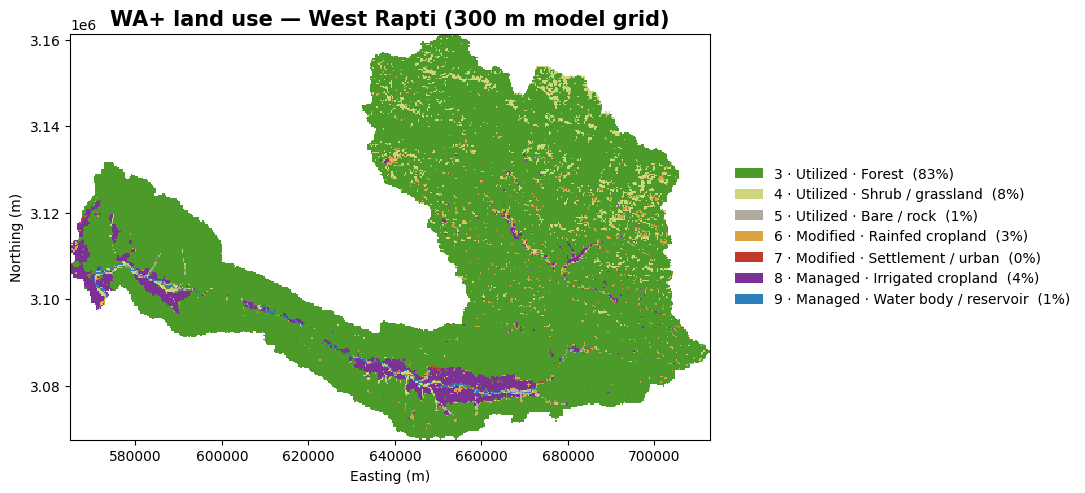

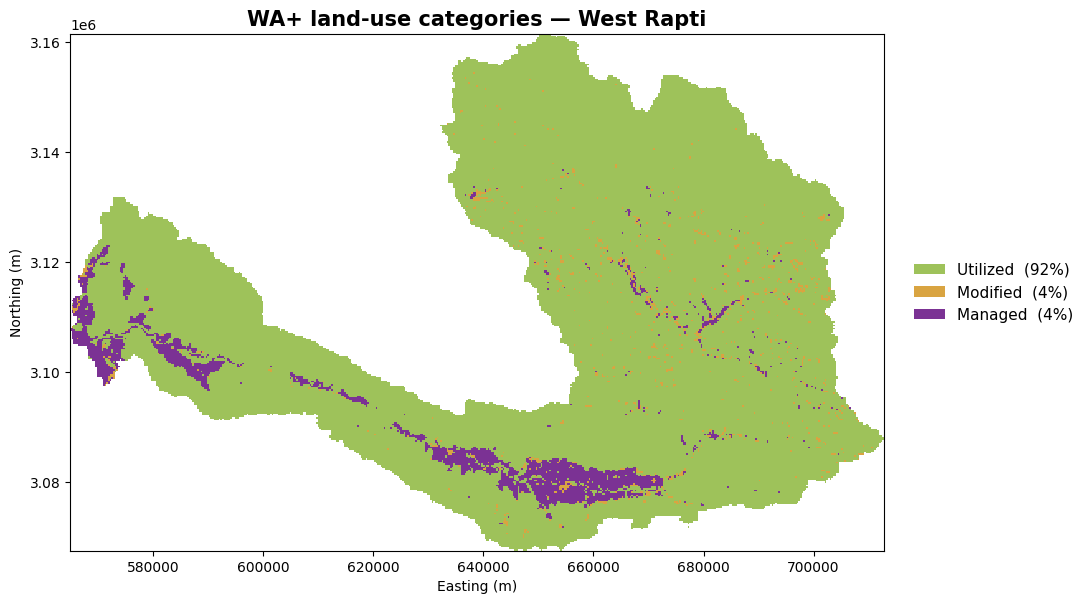

In [9]:
import os, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt, rioxarray
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.enums import Resampling
from affine import Affine
import json
import west_rapti as kw
import ee
import sys # Import sys

# Ensure OUT_DIR and KW_DIR are defined and KW_DIR is in sys.path.
# This logic is usually in an initial setup cell.
if 'OUT_DIR' not in globals():
    try:
        import google.colab; IN_COLAB = True
    except ImportError:
        IN_COLAB = False

    if IN_COLAB:
        KW_DIR = '/content/drive/MyDrive/west_rapti'
        if KW_DIR not in sys.path: # Add to sys.path if not already present
            sys.path.insert(0, KW_DIR)
    else:
        KW_DIR = '.'
    OUT_DIR = os.path.join(KW_DIR, 'outputs') if IN_COLAB else 'outputs'

# Ensure Earth Engine is initialized. It's safe to call ee.Initialize() multiple times.
# EE_PROJECT is expected to be defined by the CONFIG cell (6dd8d9bd)
# To handle potential kernel state loss:
if 'EE_PROJECT' not in globals():
    EE_PROJECT = EE_PROJECT or 'your-ee-project-id' # Default value from CONFIG cell 6dd8d9bd
    print(f"Warning: EE_PROJECT was not found in global scope. Defaulting to '{EE_PROJECT}'.")
try:
    ee.Initialize(project=EE_PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)

# To handle potential kernel state loss, ensure COMMAND_TIF is available.
# This assumes COMMAND_TIF is set in the CONFIG cell (6dd8d9bd) or updated by cell 4d84b62d.
if 'COMMAND_TIF' not in globals():
    COMMAND_TIF = '' # Default value from CONFIG cell 6dd8d9bd
    print("Warning: COMMAND_TIF was not found in global scope. Defaulting to ''.")

# Re-load dependencies from earlier cells to ensure availability
# These variables (gs, mask, region) are critical and originate from cell d3874d1a.
# kw.load_inputs ensures 'gridspec.json' and 'basin_mask.nc' are available in the current working directory.
kw.load_inputs(['gridspec.json','basin_mask.nc','dem_utm.tif','basin_config.json',
                'P_corrected.nc','ET.nc','LAI.nc','NDM.nc'], OUT_DIR)
gs = json.load(open('gridspec.json'))
BBOX = kw.lonlat_bbox(gs); UTM = gs['crs']; WA_RES = gs['res']
mask = xr.open_dataset('basin_mask.nc')['basin_mask']
region = ee.Geometry.Rectangle(BBOX)

# ============================================================
# 1. Build the 30 m WA+ land-use map (remap + command area)
# ============================================================
# §3 writes landcover_30m.tif to Drive/west_rapti (USE_EXPORT=True) or to the working folder (download);
# look in every place, wait briefly for Drive to sync, and stitch tiled exports.
import glob, time, shutil
def _export_state():
    t = dict(globals().get('tasks', [])).get('landcover_30m.tif')
    if t is None: return None, ''
    st = t.status(); return st.get('state'), st.get('error_message', '')
def _find_lc(wait_s=600):
    _t0 = globals().get('LC_EXPORT_T0')
    for t in range(0, wait_s + 1, 15):
        p = find_drive_file('landcover_30m.tif', wait_s=0, quiet=True,
                            newer_than=(_t0 - 120) if _t0 else None)
        if p: return p
        state, err = _export_state()
        if state in ('FAILED', 'CANCELLED'):
            raise RuntimeError(f'The §3 Earth Engine export {state}: {err}  — fix it and re-run §3.')
        if state is None and t >= 120:            # no export running from this session: stop after 2 min
            break
        if t < wait_s:
            print(f'   waiting for landcover_30m.tif (export: {state or "not from this session"}) ...'); time.sleep(15)
    return None
_lc = _find_lc()
assert _lc, ('landcover_30m.tif not found in outputs/, the working folder or Drive/west_rapti*. '
             'If §3 exported to Drive: Earth Engine saves exports to the Drive of the account SIGNED IN TO EARTH ENGINE — '
             'if that differs from this Colab account, the file is in the other Drive: move it to My Drive/west_rapti '
             'and re-run this cell. Also check the export FINISHED (Earth Engine Tasks list). '
             'If §3 hit a memory error, lower DL_TILE_MB / DL_TILE_DIM and re-run §3.')
os.makedirs(OUT_DIR, exist_ok=True)
for _dst in (os.path.join(OUT_DIR, 'landcover_30m.tif'), 'landcover_30m.tif'):
    if os.path.abspath(_dst) != os.path.abspath(_lc) and not os.path.exists(_dst):
        shutil.copy(_lc, _dst)
print('land cover read from:', _lc)
lc   = rioxarray.open_rasterio('landcover_30m.tif').squeeze('band', drop=True)
lu30 = kw.remap_landuse(lc, kw.WORLDCOVER_TO_WAPLUS)
# irrigation mask exported by §5 — recover it if the runtime restarted (otherwise class 8 is silently lost)
if globals().get('IRRIG_SOURCE', 'none') != 'none' and not (COMMAND_TIF and os.path.exists(COMMAND_TIF)):
    _p = find_drive_file('command_irrig.tif', wait_s=300)   # newest copy
    if _p:
        COMMAND_TIF = _p; print('irrigation mask found:', COMMAND_TIF)
    else:
        print('⚠️ NO irrigation mask (command_irrig.tif) — WA+ class 8 (irrigated) will be EMPTY. '
              'Wait for the §5 export to appear in My Drive › west_rapti and re-run this cell.')
if COMMAND_TIF and os.path.exists(COMMAND_TIF):
    cmd  = rioxarray.open_rasterio(COMMAND_TIF).squeeze('band', drop=True).rio.reproject_match(lu30)
    lu30 = kw.apply_command_area(lu30, cmd.values)          # rainfed -> irrigated inside the command area
lu30 = lu30.rio.write_crs('EPSG:32644')

# ============================================================
# 2. Names, colours, categories from WAPLUS_CLASSES {code:(cat, sub)}
# ============================================================
CATEGORY    = {c: cat for c,(cat,sub) in kw.WAPLUS_CLASSES.items()}
CLASS_NAMES = {c: f'{cat} · {sub}' for c,(cat,sub) in kw.WAPLUS_CLASSES.items()}
CAT_ORDER   = ['Protected','Utilized','Modified','Managed']
WAPLUS_COLORS   = {1:'#eaf0f4',2:'#0b4d24',3:'#4c9a2a',4:'#cdd67a',5:'#b0a99f',
                   6:'#d9a441',7:'#c0392b',8:'#7b3294',9:'#2c7fb8'}
CATEGORY_COLORS = {'Protected':'#1a6b3c','Utilized':'#9ec25a','Modified':'#d9a441','Managed':'#7b3294'}

# ============================================================
# 3. Aggregate 30 m -> 300 m as per-class AREA FRACTIONS (robust; exact areas)
# ============================================================
tgt = xr.DataArray(
        np.zeros((gs['height'], gs['width']), 'float32'), dims=('y','x'),
        coords={'y': gs['te'][3]-(np.arange(gs['height'])+0.5)*gs['res'],
                'x': gs['te'][0]+(np.arange(gs['width'])+0.5)*gs['res']}
      ).rio.write_crs(gs['crs']).rio.write_transform(
        Affine(gs['res'],0,gs['te'][0],0,-gs['res'],gs['te'][3]))

codes = [int(c) for c in np.unique(np.asarray(lu30)) if int(c) != 0]
frac  = {c: (lu30 == c).astype('float32').rio.write_crs('EPSG:32644')
              .rio.reproject_match(tgt, resampling=Resampling.average)   # = areal fraction per 300 m cell
         for c in codes}
fstack = xr.concat([frac[c] for c in codes], dim='k').assign_coords(k=('k', codes))
basin  = (mask == 1)
cell_ha = gs['res']**2 / 1e4                                              # 300 m -> 9 ha

# ============================================================
# 4. Categorical model grid (engine needs lu == cls); protect cropland
#    argmax dominant class, then force Modified/Managed cropland where its
#    fraction is meaningful, so Sheet 2/4 don't lose the command area.
# ============================================================
CROP_FRAC_MIN = 0.33     # a 300 m cell >=33% rainfed  -> label rainfed (6)
IRR_FRAC_MIN  = 0.20     # a 300 m cell >=20% irrigated -> label irrigated (8)   (set >1 to disable)
codes_arr = np.array(codes)
dom = codes_arr[fstack.fillna(0).argmax('k').values]                     # dominant class per cell
present_any = fstack.sum('k').values > 0.01
luc = np.where(present_any, dom, 0).astype('int16')
if 6 in frac: luc = np.where(frac[6].values >= CROP_FRAC_MIN, 6, luc)    # rainfed priority
if 8 in frac: luc = np.where(frac[8].values >= IRR_FRAC_MIN, 8, luc)     # irrigated priority (highest)
lu = tgt.copy(data=luc).astype('int16'); lu.name = 'lu'
lu.rio.write_nodata(0, inplace=True)
lu.to_netcdf('lu.nc')
assert os.path.exists('lu.nc'), 'lu.nc failed to write.'

# ============================================================
# 5. AREA TABLE — from the exact fractions (this is the truth for the brief)
# ============================================================
rows = [{'code': c, 'category': CATEGORY[c], 'class': CLASS_NAMES[c],
         'area_ha':  float(frac[c].where(basin).sum()) * cell_ha,
         'area_km2': float(frac[c].where(basin).sum()) * cell_ha / 100.0}
        for c in codes]
area = pd.DataFrame(rows)
area = area[area['area_ha'] > 0].copy()
area['category'] = pd.Categorical(area['category'], CAT_ORDER, ordered=True)
area = area.sort_values(['category','code']).reset_index(drop=True)
area['pct'] = 100 * area['area_ha'] / area['area_ha'].sum()
area.to_csv('waplus_areas.csv', index=False)
cat_area = area.groupby('category', observed=True)[['area_ha','area_km2','pct']].sum().reindex(CAT_ORDER).dropna()
cat_area.to_csv('waplus_areas_by_category.csv')

print('=== WA+ land-use areas — West Rapti (areal fractions, 30 m truth) ===')
print(area[['code','class','area_ha','area_km2','pct']].to_string(index=False,
      formatters={'area_ha':'{:,.0f}'.format,'area_km2':'{:,.1f}'.format,'pct':'{:.1f}%'.format}))
print('-'*56)
print(cat_area.to_string(formatters={'area_ha':'{:,.0f}'.format,'area_km2':'{:,.1f}'.format,'pct':'{:.1f}%'.format}))
print(f"TOTAL  {area['area_ha'].sum():,.0f} ha   {area['area_km2'].sum():,.1f} km²   (expect ~5,200 km² at Kusum)")

# how much the categorical model grid differs from the fractional truth (transparency)
luc_b = lu.where(basin); u,cn = np.unique(np.asarray(luc_b), return_counts=True)
catg = {int(k): int(v) for k,v in zip(u,cn) if np.isfinite(k) and int(k)!=0}; tt=sum(catg.values())
print('\ncategorical model grid vs fractional truth (%):')
for c in codes:
    print(f"  {c} {CLASS_NAMES[c]:<34} model {100*catg.get(c,0)/tt:5.1f}   truth {area.loc[area.code==c,'pct'].squeeze() if c in area.code.values else 0:5.1f}")

# ============================================================
# 6. Maps — detailed 9-class + 4-category (both from the categorical model grid)
# ============================================================
def discrete_map(codes_present, colors, title, labels):
    lub = lu.where(basin, drop=True)                 # keep coords -> correct N-up orientation
    arr = np.asarray(lub, float)
    im  = np.full(arr.shape, np.nan)
    for i, c in enumerate(codes_present):
        im[arr == c] = i
    idx = lub.copy(data=im)                           # <-- preserves y/x coords (was the flip)
    fig, ax = plt.subplots(figsize=(11, 9))
    idx.plot(ax=ax, cmap=ListedColormap([colors[c] for c in codes_present]),
             vmin=-0.5, vmax=len(codes_present)-0.5, add_colorbar=False)
    ax.set_aspect('equal'); ax.set_title(title, fontsize=15, weight='bold')
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
    ax.legend(handles=[Patch(facecolor=colors[c], label=labels[c]) for c in codes_present],
              loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=10)
    plt.tight_layout(); plt.show()

present = [c for c in codes if c in catg]
discrete_map(present, WAPLUS_COLORS, 'WA+ land use — West Rapti (300 m model grid)',
             {c: f"{c} · {CLASS_NAMES[c]}  ({area.loc[area.code==c,'pct'].squeeze():.0f}%)" for c in present})

# category map — same coord-preserving pattern
lub = lu.where(basin, drop=True); arr = np.asarray(lub, float)
cat_present = [k for k in CAT_ORDER if k in set(CATEGORY[c] for c in present)]
cim = np.full(arr.shape, np.nan)
for i, k in enumerate(cat_present):
    for c in present:
        if CATEGORY[c] == k: cim[arr == c] = i
cidx = lub.copy(data=cim)
fig, ax = plt.subplots(figsize=(11, 9))
cidx.plot(ax=ax, cmap=ListedColormap([CATEGORY_COLORS[k] for k in cat_present]),
          vmin=-0.5, vmax=len(cat_present)-0.5, add_colorbar=False)
ax.set_aspect('equal'); ax.set_title('WA+ land-use categories — West Rapti', fontsize=15, weight='bold')
ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
ax.legend(handles=[Patch(facecolor=CATEGORY_COLORS[k], label=f"{k}  ({cat_area.loc[k,'pct']:.0f}%)") for k in cat_present],
          loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=11)
plt.tight_layout(); plt.show()

### 🔎 Optional — no irrigated pixels? Follow the mask from Earth Engine to WA+ class 8

Irrigation can disappear at four steps: (1) the mask file is missing or empty, (2) the sources find no irrigation in the box, (3) the mask does not overlap WorldCover **cropland** (only cropland can become class 8 — terraced fields mapped as grass or shrub are missed), or (4) the fields are too scattered to reach `IRR_FRAC_MIN` of a 300 m cell. The step where the number drops to zero is the cause.

In [10]:
# --- why no irrigated pixels? follow the mask from Earth Engine to WA+ class 8 ---
import os, glob, numpy as np, rioxarray, ee
print('1) irrigation mask file')
cands = sorted({p for d in _export_dirs() for p in glob.glob(os.path.join(d, 'command_irrig*.tif'))})
print('   files found:', cands or 'NONE', '\n   COMMAND_TIF in use:', COMMAND_TIF or '(empty)')
if COMMAND_TIF and os.path.exists(COMMAND_TIF):
    _m = rioxarray.open_rasterio(COMMAND_TIF).squeeze('band', drop=True)
    _v, _n = np.unique(np.asarray(_m), return_counts=True)
    print('   pixel values:', dict(zip(_v.tolist(), _n.tolist())), '| CRS', _m.rio.crs, '| shape', _m.shape)

print('2) irrigated area per source inside the box (Earth Engine, km²)')
_px = ee.Image.pixelArea().divide(1e6)
for _name in ('lgrip30', 'worldcereal', 'gfsad', 'detect'):
    try:
        _a = _px.updateMask(SRC[_name]().unmask(0).eq(1)).reduceRegion(
            ee.Reducer.sum(), region_geom, 100, maxPixels=1e10, tileScale=4).get('area').getInfo()
        print(f'   {_name:12s} {(_a or 0):9.1f}')
    except Exception as e:
        print(f'   {_name:12s} error: {str(e)[:100]}')

print('3) overlap with WorldCover cropland (only cropland can become class 8)')
_lc = rioxarray.open_rasterio('landcover_30m.tif').squeeze('band', drop=True)
_crop = np.asarray(_lc) == 40
print(f'   WorldCover cropland in the box: {_crop.sum() * 900 / 1e6:,.1f} km²')
if COMMAND_TIF and os.path.exists(COMMAND_TIF):
    _cm = rioxarray.open_rasterio(COMMAND_TIF).squeeze('band', drop=True).rio.reproject_match(_lc)
    _irr = np.asarray(_cm) == 1
    print(f'   irrigated in the mask: {_irr.sum() * 900 / 1e6:,.1f} km²  |  of which on WorldCover cropland: '
          f'{(_irr & _crop).sum() * 900 / 1e6:,.1f} km²')

print('4) after aggregation to the 300 m grid')
if 'frac' in globals() and 8 in frac:
    _f8 = frac[8].where(mask == 1)
    print(f'   class 8 in the basin (exact fractions): {float(_f8.sum()) * 0.09:,.1f} km²  |  '
          f'300 m cells labelled 8 (≥ IRR_FRAC_MIN = {IRR_FRAC_MIN}): {int((_f8 >= IRR_FRAC_MIN).sum())}')
elif 'frac' in globals():
    print('   no class 8 even at 30 m — the cause is in step 1, 2 or 3')
else:
    print('   run the land-use cell first')

1) irrigation mask file
   files found: ['/content/drive/MyDrive/west_rapti/command_irrig.tif'] 
   COMMAND_TIF in use: /content/drive/MyDrive/west_rapti/command_irrig.tif
   pixel values: {0: 19770766, 1: 4630364} | CRS EPSG:32644 | shape (4218, 5785)
2) irrigated area per source inside the box (Earth Engine, km²)
   lgrip30         4167.4
   worldcereal     1038.9
   gfsad           3333.2
   detect           171.4
3) overlap with WorldCover cropland (only cropland can become class 8)
   WorldCover cropland in the box: 3,986.7 km²
   irrigated in the mask: 4,167.3 km²  |  of which on WorldCover cropland: 3,128.6 km²
4) after aggregation to the 300 m grid
   class 8 in the basin (exact fractions): 225.7 km²  |  300 m cells labelled 8 (≥ IRR_FRAC_MIN = 0.2): 3728


**Diagnostic — how much irrigation is actually inside the basin?** Compares irrigated area
in the whole download box vs inside the Kusum catchment. If almost all of it is out-of-basin, the
command area is downstream of the outlet (an outlet-choice question, not a mapping bug).

In [11]:
import numpy as np
irr30 = (lu30 == 8).astype('float32').rio.write_crs('EPSG:32644')
inb   = float(irr30.rio.reproject_match(tgt, resampling=Resampling.average).where(mask==1).sum())*9
tot   = int((np.asarray(lu30)==8).sum())*0.09
print(f'irrigated total (rectangle): {tot:,.0f} ha | inside Kusum basin: {inb:,.0f} ha '
      f'({100*inb/tot:.1f}% of it is in-basin)')

irrigated total (rectangle): 312,856 ha | inside Kusum basin: 22,568 ha (7.2% of it is in-basin)


### ✅ Checkpoint 2
Glacier/snow only at high elevation; water where Sentinel-1 agrees; irrigated cropland present in the command area. The land-use map is the backbone of every WA+ sheet — get the classes right here.

## 6 · Assemble the analysis-ready cube (freeze it)

Confirm every cube is on the canonical grid, then write the data-cube + land-use paths into `basin_config.json`. Record each product's native resolution in the assumptions log.

In [12]:
cubes = {'p':'P_corrected.nc','et':'ET.nc','lai':'LAI.nc','ndm':'NDM.nc'}
need = list(cubes.values()) + ['lu.nc']
missing = [f for f in need if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(
        'Missing inputs for the cube: %s. Run the sections that create them first — '
        'P_corrected/ET/LAI/NDM come from Lab 2 (copy them into this session or re-run Lab 2), '
        'and lu.nc is written by §5 above (which needs §3 to have downloaded the map).' % missing)
bad = kw.check_same_grid(need, gs)
print('off-grid files:', bad or 'none — all aligned')
bc = kw.assemble_cube(cubes, lu_nc='lu.nc')
print('BASIN data_cube:', {k:v for k,v in bc['data_cube']['monthly'].items() if v})
print('BASIN gis_data lu:', bc['gis_data'].get('lu'))

off-grid files: [('P_corrected.nc', (None, None)), ('ET.nc', (None, None)), ('LAI.nc', (None, None)), ('NDM.nc', (None, None))]
BASIN data_cube: {'p': 'P_corrected.nc', 'et': 'ET.nc', 'lai': 'LAI.nc', 'ndm': 'NDM.nc'}
BASIN gis_data lu: lu.nc


## 7 · Save outputs to Drive

In [13]:
saved = kw.save_outputs(['landcover_30m.tif','lu.nc','basin_config.json'], OUT_DIR)
print('saved to', OUT_DIR, '->', saved)

saved to /content/drive/MyDrive/west_rapti/outputs -> ['landcover_30m.tif', 'lu.nc', 'basin_config.json']


## What feeds Lab 4
`lu.nc` (land use) + the frozen cube in `basin_config.json` drive the hydroloop soil-moisture balance: root depth and SMmax are parameterised per WA+ class, and the green/blue ET split is computed per pixel.

## 8 · Interactive — see the classification live & click to inspect  🖱️

Put the map you just built on a **zoomable Earth-Engine map**, side by side with ESA WorldCover and a class legend, and **click any pixel** to read its class (yours vs WorldCover). It reuses the `classified` and `wc` images from §3 — nothing to download — so you can eyeball where the classifier is confident or confused (look hardest at cropland and water) before you trust the 30 m map and its accuracy table above.

In [14]:
import os # Ensure os is imported for path checks
import json # Ensure json is imported for json.dumps

# --- live land-cover map (RF vs WorldCover) + legend + click-to-inspect ---
import geemap
CLS  = [10,20,30,40,50,60,70,80,90,95,100]
NAME = {10:'Tree',20:'Shrub',30:'Grass',40:'Cropland',50:'Built',60:'Bare',
        70:'Snow/Ice',80:'Water',90:'Wetland',95:'Mangrove',100:'Moss/lichen'}
PAL  = ['006400','ffbb22','ffff4c','f096ff','fa0000','b4b4b4','f0f0f0','0064c8','0096a0','00cf75','fae6a0']

# --- basin_geom: zoom the live map to the watershed extent ---
from pyproj import Transformer as _Tr
_mb = mask.where(mask==1, drop=True)
_xs, _ys = _mb[mask.dims[-1]].values, _mb[mask.dims[-2]].values
_lon, _lat = _Tr.from_crs(UTM, "EPSG:4326", always_xy=True).transform([_xs.min(),_xs.max(),_xs.min(),_xs.max()], [_ys.min(),_ys.min(),_ys.max(),_ys.max()])
basin_geom = ee.Geometry.Rectangle([min(_lon),min(_lat),max(_lon),max(_lat)])
Mc = geemap.Map(basemap='Esri.WorldImagery'); Mc.centerObject(basin_geom, 9)
Mc.addLayer(ee.ImageCollection('ESA/WorldCover/v200').first(), {'bands':['Map']}, 'WorldCover (reference)', False)
_disp = classified.remap(CLS, list(range(len(CLS))))
Mc.addLayer(_disp, {'min':0,'max':len(CLS)-1,'palette':PAL}, 'Land cover (this run)', True)

# irrigation mask overlay, if §4d built one
try:
    # Check if COMMAND_TIF is defined and the file exists locally
    if 'COMMAND_TIF' in globals() and os.path.exists(COMMAND_TIF):
        # Use geemap.add_raster to display the local GeoTIFF file.
        # This bypasses the Earth Engine computation for this layer, using the already exported file.
        # For a binary mask (0 or 1), we map value 1 to blue and make 0 transparent.
        Mc.add_raster(COMMAND_TIF, layer_name=f'Irrigated ({IRRIG_SOURCE})', expression='array([0, 194, 255, 255]).astype("uint8") if b1 == 1 else array([0, 0, 0, 0]).astype("uint8")', nodata=0, shown=True, opacity=0.7)
    elif irr is not None:
        # Fallback if COMMAND_TIF is not available or file doesn't exist.
        # Attempt to display the EE object, but reproject it to a coarser resolution
        # to reduce the computational load and minimize the chance of a timeout.
        display_irr_for_map = irr.reproject(crs=irr.projection(), scale=100).selfMask() # Reproject to 100m for display
        Mc.addLayer(display_irr_for_map, {'palette':['00c2ff']}, f'Irrigated ({IRRIG_SOURCE}) (coarse)', True)
except NameError:
    pass

Mc.addLayer(region, {'color':'ffffff'}, 'Basin box', True)
Mc.add_legend(title='Land cover', builtin_legend='ESA_WorldCover')

_wc_map = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map')
def _inspect(**k):
    if k.get('type') != 'click': return
    lat, lon = k['coordinates']; pt = ee.Geometry.Point([lon, lat])
    try:
        rf = classified.reduceRegion(ee.Reducer.first(), pt, 30).getInfo().get('Map')
        wv = _wc_map.reduceRegion(ee.Reducer.first(), pt, 10).getInfo().get('Map')
        print(f'@ lon={lon:.3f}, lat={lat:.3f}  ->  this run: {NAME.get(rf, rf)}   |   WorldCover: {NAME.get(wv, wv)}')
    except Exception as e:
        print('inspect error:', e)
Mc.on_interaction(_inspect)
print('Toggle WorldCover vs this run (top-right); click a pixel to compare classes.')
Mc

Toggle WorldCover vs this run (top-right); click a pixel to compare classes.


Map(center=[28.147968096230915, 82.41690764101794], controls=(WidgetControl(options=['position', 'transparent_…